# 16-385 Computer Vision

## Programming Assignment 3: 3D Reconstruction

In this assignment, you will be implementing an algorithm to reconstruct a 3D point cloud from a pair of images taken at different points of view. Specifically, you will implement the 8-point algorithm, triangulation, and other techniques to find and visualize 3D locations of corresponding image points.

---
## Instructions

1. **Integrity and collaboration:** Students are encouraged to work in groups but each student must submit their own work. If you work as a group, include the names of your collaborators in your write up. Code should NOT be shared or copied. Please DO NOT use external code unless permitted. Plagiarism is strongly prohibited and may lead to failure of this course.

2. **Start early!** Especially those not familiar with Python.

3. **Questions:** If you have any questions, please look at Piazza first. Other students may have encountered the same problem, and it may be solved already. If not, post your question on the discussion board. Teaching staff will respond as soon as possible.

4. **File paths:** Excluding the assignment setup, please make sure that any file paths that you use are relative and not absolute. Not `cv2.imread('/content/drive/MyDrive/hw1/data/xyz.jpg')` but `cv2.imread('./data/xyz.jpg')`.

5. **Submission:** Handing in your assignments involves **two** separate submissions via Gradescope: one for your code + results, and one for a pdf version of your code showing any requested results. The submission time will be the later of the two timestamps associated with these submissions. For example, if you submit your full solution before the deadline and submit your write-up 1 day late, your assignment will be considered 1 day late. Once submitted, **double check that the pdf can be viewed from within Gradescope and that you submitted the correct files!!**


### Assignment Setup
Run the next cell to use the bundled files. Local Jupyter uses this repository; Google Colab clones it without requiring Google Drive access.


In [ ]:
from pathlib import Path
import os
import subprocess
import sys

# Find the complete bundle when launched from the repository or an assignment folder.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "requirements.txt").is_file()
                  and all((p / f"hw{i}").is_dir() for i in range(4))), None)
if REPO_ROOT is None and Path("/content").is_dir():
    try:
        import google.colab
    except ImportError:
        pass
    else:
        REPO_ROOT = Path("/content/CMU-16-385-Computer-Vision")
        if not REPO_ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1",
                            "https://github.com/pedier/CMU-16-385-Computer-Vision.git",
                            str(REPO_ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(REPO_ROOT / "requirements.txt")], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Clone the complete repository and launch Jupyter from it.")
os.chdir(REPO_ROOT / "hw3")
Path("results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())


In [ ]:
# All assignment assets are already included in this repository.


Now run the following code to import the modules and function definitions you will need for this assignment.

In [ ]:
import os
import numpy as np
import scipy
import scipy.optimize
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import cv2


connections_3d = [[0,1], [1,3], [2,3], [2,0], [4,5], [6,7], [8,9], [9,11], [10,11], [10,8], [0,4], [4,8],
                  [1,5], [5,9], [2,6], [6,10], [3,7], [7,11]]
color_links = [(255,0,0),(255,0,0),(255,0,0),(255,0,0),(0,0,255),(255,0,255),(0,255,0),(0,255,0),(0,255,0),(0,255,0),(0,0,255),(0,0,255),(0,0,255),(0,0,255),(255,0,255),(255,0,255),(255,0,255),(255,0,255)]
colors = ['blue','blue','blue','blue','red','magenta','green','green','green','green','red','red','red','red','magenta','magenta','magenta','magenta']


def visualize_keypoints(image, pts, Threshold=100):
    '''
    This function visualizes the 2d keypoint pairs in connections_3d
    (as define above) whose match score lies above a given Threshold
    in an OpenCV GUI frame, against an image background.

    :param image: image as a numpy array, of shape (height, width, 3) where 3 is the number of color channels
    :param pts: np.array of shape (num_points, 3)
    '''
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    for i in range(12):
        cx, cy = pts[i][0:2]
        if pts[i][2]>Threshold:
            cv2.circle(image,(int(cx),int(cy)),5,(0,255,255),5)

    for i in range(len(connections_3d)):
        idx0, idx1 = connections_3d[i]
        if pts[idx0][2]>Threshold and pts[idx1][2]>Threshold:
            x0, y0 = pts[idx0][0:2]
            x1, y1 = pts[idx1][0:2]
            cv2.line(image, (int(x0), int(y0)), (int(x1), int(y1)), color_links[i], 2)

    plt.imshow(image)
    plt.show()

    return image


def plot_3d_keypoint(pts_3d):
    '''
    this function visualizes 3d keypoints on a matplotlib 3d axes

    :param pts_3d: np.array of shape (num_points, 3)
    '''
    fig = plt.figure()
    num_points = pts_3d.shape[0]
    ax = fig.add_subplot(111, projection='3d')
    for j in range(len(connections_3d)):
        index0, index1 = connections_3d[j]
        xline = [pts_3d[index0,0], pts_3d[index1,0]]
        yline = [pts_3d[index0,1], pts_3d[index1,1]]
        zline = [pts_3d[index0,2], pts_3d[index1,2]]
        ax.plot(xline, yline, zline, color=colors[j])
    np.set_printoptions(threshold=1e6, suppress=True)
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')
    plt.show()


def calc_epi_error(pts1_homo, pts2_homo, F):
    '''
    Helper function to calcualte the sum of squared distance between the
    corresponding points and the estimated epipolar lines.

    pts1_homo \dot F.T \dot pts2_homo = 0

    :param pts1_homo: of shape (num_points, 3); in homogeneous coordinates, not normalized.
    :param pts2_homo: same specification as to pts1_homo.
    :param F: Fundamental matrix
    '''

    line1s = pts1_homo.dot(F.T)
    dist1 = np.square(np.divide(np.sum(np.multiply(
        line1s, pts2_homo), axis=1), np.linalg.norm(line1s[:, :2], axis=1)))

    line2s = pts2_homo.dot(F)
    dist2 = np.square(np.divide(np.sum(np.multiply(
        line2s, pts1_homo), axis=1), np.linalg.norm(line2s[:, :2], axis=1)))

    ress = (dist1 + dist2).flatten()
    return ress


def toHomogenous(pts):
    """
    Adds a stack of ones at the end, to turn a set of points into a set of
    homogeneous points.

    :params pts: in shape (num_points, 2).
    """
    return np.vstack([pts[:,0],pts[:,1],np.ones(pts.shape[0])]).T.copy()


def _epipoles(E):
    """
    gets the epipoles from the Essential Matrix.

    :params E: Essential matrix.
    """
    U, S, V = np.linalg.svd(E)
    e1 = V[-1, :]
    U, S, V = np.linalg.svd(E.T)
    e2 = V[-1, :]
    return e1, e2


def displayEpipolarF(I1, I2, F, points):
    """
    GUI interface you may use to help you verify your calculated fundamental
    matrix F. Select a point I1 in one view, and it should correctly correspond
    to the displayed point in the second view.
    """
    e1, e2 = _epipoles(F)

    sy, sx, _ = I2.shape

    f, [ax1, ax2] = plt.subplots(1, 2, figsize=(12, 9))
    ax1.imshow(I1)
    ax1.set_title('The point you selected:')
    ax2.imshow(I2)
    ax2.set_title('Verify that the corresponding point \n is on the epipolar line in this image')

    plt.sca(ax1)

    colors = ['r','g','b','y','m','k']
    for i, out in enumerate(points):
      x, y = out #[0]

      xc = x
      yc = y
      v = np.array([xc, yc, 1])
      l = F.dot(v)
      s = np.sqrt(l[0]**2+l[1]**2)

      if s==0:
          print('Zero line vector in displayEpipolar')

      l = l/s

      if l[0] != 0:
          ye = sy-1
          ys = 0
          xe = -(l[1] * ye + l[2])/l[0]
          xs = -(l[1] * ys + l[2])/l[0]
      else:
          xe = sx-1
          xs = 0
          ye = -(l[0] * xe + l[2])/l[1]
          ys = -(l[0] * xs + l[2])/l[1]

      # plt.plot(x,y, '*', 'MarkerSize', 6, 'LineWidth', 2);
      ax1.plot(x, y, '*', markersize=6, linewidth=2, color=colors[i%len(colors)])
      ax2.plot([xs, xe], [ys, ye], linewidth=2, color=colors[i%len(colors)])
    plt.draw()


def _singularize(F):
    U, S, V = np.linalg.svd(F)
    S[-1] = 0
    F = U.dot(np.diag(S).dot(V))
    return F

def _objective_F(f, pts1, pts2):
    F = _singularize(f.reshape([3, 3]))
    num_points = pts1.shape[0]
    hpts1 = np.concatenate([pts1, np.ones([num_points, 1])], axis=1)
    hpts2 = np.concatenate([pts2, np.ones([num_points, 1])], axis=1)
    Fp1 = F.dot(hpts1.T)
    FTp2 = F.T.dot(hpts2.T)

    r = 0
    for fp1, fp2, hp2 in zip(Fp1.T, FTp2.T, hpts2):
        r += (hp2.dot(fp1))**2 * (1/(fp1[0]**2 + fp1[1]**2) + 1/(fp2[0]**2 + fp2[1]**2))
    return r

def refineF(F, pts1, pts2):
    f = scipy.optimize.fmin_powell(
        lambda x: _objective_F(x, pts1, pts2), F.reshape([-1]),
        maxiter=100000,
        maxfun=10000,
        disp=False
    )
    return _singularize(f.reshape([3, 3]))


# Used for Epipolar Correspondence
def epipolarMatchGUI(I1, I2, F, points, epipolarCorrespondence):
    e1, e2 = _epipoles(F)

    sy, sx, _ = I2.shape

    f, [ax1, ax2] = plt.subplots(1, 2, figsize=(12, 9))
    ax1.imshow(I1)
    ax1.set_title('The point you selected:')
    ax2.imshow(I2)
    ax2.set_title('Verify that the corresponding point \n is on the epipolar line in this image \nand that the corresponding point matches')

    plt.sca(ax1)

    colors = ['r','g','b','y','m','k']

    for i, out in enumerate(points):
      x, y = out

      xc = int(x)
      yc = int(y)
      v = np.array([xc, yc, 1])
      l = F.dot(v)
      s = np.sqrt(l[0]**2+l[1]**2)

      if s==0:
          print('Zero line vector in displayEpipolar')

      l = l/s

      if l[0] != 0:
          ye = sy-1
          ys = 0
          xe = -(l[1] * ye + l[2])/l[0]
          xs = -(l[1] * ys + l[2])/l[0]
      else:
          xe = sx-1
          xs = 0
          ye = -(l[0] * xe + l[2])/l[1]
          ys = -(l[0] * xs + l[2])/l[1]

      ax1.plot(x, y, '*', markersize=6, linewidth=2, color=colors[i%len(colors)])
      ax2.plot([xs, xe], [ys, ye], linewidth=2, color=colors[i%len(colors)])

      # draw points
      x2, y2 = epipolarCorrespondence(I1, I2, F, xc, yc)
      ax2.plot(x2, y2, 'ro', markersize=8, linewidth=2)
      plt.draw()



<>:71: SyntaxWarning: invalid escape sequence '\d'
<>:71: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1780/2716864507.py:71: SyntaxWarning: invalid escape sequence '\d'
  pts1_homo \dot F.T \dot pts2_homo = 0


---
## Section 1: The Fundamental Matrix

In this part, you will begin by implementing the 8-point algorithm seen in class to estimate the fundamental matrix from corresponding points in two images. Next, given the fundamental matrix and calibrated intrinsics (which are provided) you will compute the essential matrix and use this to compute a 3D metric reconstruction from 2D correspondences using triangulation. Then, you will implement a method to automatically match points taking advantage of epipolar constraints and make a 3D visualization of the results. Finally, you will implement bundle adjustment to further improve your algorithm.

### 1.1 Estimating the Fundamental Matrix with the Eight-point Algorithm (10 points)

In this section, you will estimate the fundamental matrix given a pair of images using the Eight-Point Algorithm. In the $\texttt{data/}$ directory, you will find two images (see Figure 1 below) from the [Middlebury multi-view dataset](http://vision.middlebury.edu/mview/data/), which is used to evaluate the performance of modern 3D reconstruction algorithms.

![Figure 1](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw3/fig3.png)
*Figure 1:* "Temple" images for this assignment.

The 8-point algorithm is arguably the simplest method for estimating the fundamental matrix. For this section, you can use provided correspondences you can find in *data/some_corresp.npz*. Implement the function:
```
F = eightpoint(pts1, pts2, M)
```
where `pts1` and `pts2` are `N x 2` matrices corresponding to the `(x,y)` coordinates of the `N` points in the first and second image, respectively. `M` is a scale parameter, representing the maximum of the image width and height.

- You should scale the data as was discussed in class, by dividing each coordinate by `M` (the maximum of the image's width and height). After computing `F`, you will have to *"unscale"* the fundamental matrix. *Hint:* If $x_{normalized} = \mathbf{T}x$, then $F_{unnormalized} = \mathbf{T}^T \mathbf{F} \mathbf{T}$. You must enforce the singularity condition of `F` before unscaling.

- You may find it helpful to refine the solution by using local minimization.  This probably won't fix a completely broken solution, but may make a good solution better by locally minimizing a geometric cost function. For this, we provide a helper function `refineF` that takes in `F` and the two sets of points, which you can call from `eightpoint` before unscaling `F`.

- Remember that the x-coordinate of a point in the image is its column entry, and y-coordinate is the row entry. Also note that eight-point is just a figurative name, it just means that you need at least 8 points; your algorithm should use an over-determined system (`N > 8` points).

In [ ]:
def eightpoint(pts1, pts2, M):
  '''
  Q1.1: Eight Point Algorithm
  Input:  pts1, Nx2 Matrix
          pts2, Nx2 Matrix
          M, a scalar parameter computed as max(imwidth, imheight)
  Output: F, the fundamental matrix

  HINTS:
  (1) Normalize the input pts1 and pts2 using the matrix T.
  (2) Setup the eight point algorithm's equation.
  (3) Solve for the least square solution using SVD.
  (4) Use the function `_singularize` (provided in the helper functions above) to enforce the singularity condition.
  (5) Use the function `refineF` (provided in the helper functions above) to refine the computed fundamental matrix.
      (Remember to use the normalized points instead of the original points)
  (6) Unscale the fundamental matrix by the lower right corner element
  '''

  # let's first define our T
  T = np.diag([1/M, 1/M, 1])

  pts1_norm = pts1 / M  # (N, 2)
  pts2_norm = pts2 / M  # (N, 2)

  x1, y1 = pts1_norm.T
  x2, y2 = pts2_norm.T

  A = np.vstack([x2 * x1, x2 * y1, x2,
          y2 * x1, y2 * y1, y2,
          x1, y1, np.ones(len(pts1))]).T

  _, _, Vt = np.linalg.svd(A)
  F = Vt[-1].reshape(3, 3)
  F = _singularize(F)
  F = refineF(F, pts1_norm, pts2_norm)
  F = T.T @ F @ T
  F = F / F[2, 2]   # we need F[2, 2] == 1

  return F

Run this code to test your implementation of the 8-point algorithm. Your code should pass all the assert statements at the end.

In [ ]:
correspondence = np.load('data/some_corresp.npz') # Loading correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')

F = eightpoint(pts1, pts2, M=np.max([*im1.shape, *im2.shape]))
print(f'recovered F:\n{F.round(4)}')

# Simple Tests to verify your implementation:
pts1_homogenous, pts2_homogenous = toHomogenous(pts1), toHomogenous(pts2)

assert F.shape == (3, 3), "F is wrong shape"
assert F[2, 2] == 1, "F_33 != 1"
assert np.linalg.matrix_rank(F) == 2, "F should have rank 2"
assert np.mean(calc_epi_error(pts1_homogenous, pts2_homogenous, F)) < 1, "F error is too high to be accurate"

recovered F:
[[-0.      0.     -0.2519]
 [ 0.     -0.      0.0026]
 [ 0.2422 -0.0068  1.    ]]


The following tool may help you debug. You may specify a point in `im1`, and view the corresponding epipolar line in `im2` based on the `F` you found. In your submission, **make sure you include the debug picture below, with at least five epipolar point-line correspondences that show that your calculation of `F` is correct.**



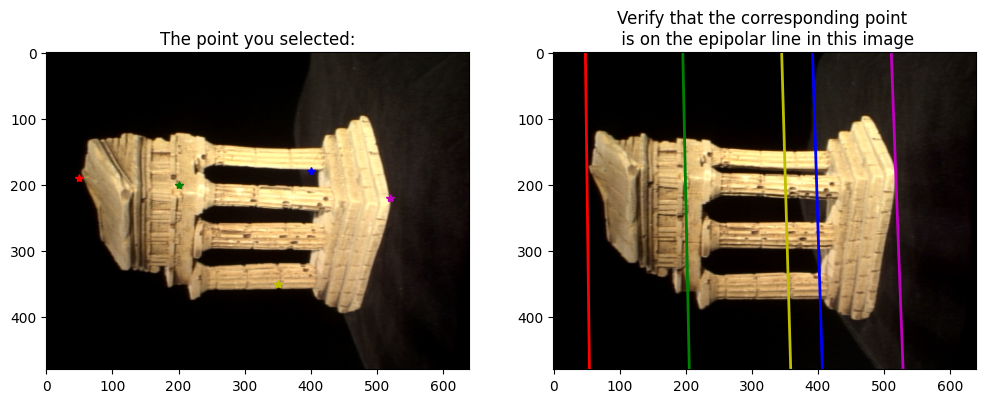

In [ ]:
# the points in im1, whose correnponding epipolar line in im2 you'd like to verify
point = [(50,190),(200, 200), (400,180), (350,350), (520, 220)]
# feel free to change these point, to verify different point correspondences
displayEpipolarF(im1, im2, F, point)

---
## Section 2: Metric Reconstruction

In this problem, you will compute the projective camera matrices and triangulate the 2D point pairs from the image pair to obtain the 3D scene structure of the temple object. To obtain the 3D scene structure, first convert the fundamental matrix `F` to an essential matrix `E`. Examine the lecture notes to find out how to do this when the internal camera calibration matrices `K1` and `K2` are known (also known as the intrinsic matrices). These are provided in *data/intrinsics.npz*.

### 2.1 Estimating the Essential Matrix (5 points)

Complete the function `essentialMatrix` to compute the essential matrix `E` given `F`, `K1` and `K2` with the signature:
```
E = essentialMatrix(F, K1, K2)
```

In [ ]:
def essentialMatrix(F, K1, K2):
  '''
  Q2.1: Compute the essential matrix E.
    Input:  F, fundamental matrix
            K1, internal camera calibration matrix of camera 1
            K2, internal camera calibration matrix of camera 2
    Output: E, the essential matrix
  '''
  E = K2.T @ F @ K1
  E = E / E[2, 2]

  return E

Run the following code to check your implementation.

In [ ]:
correspondence = np.load('data/some_corresp.npz') # Loading correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')

F = eightpoint(pts1, pts2, M=np.max([*im1.shape, *im2.shape]))
E = essentialMatrix(F, K1, K2)
print(f'recovered E:\n{E.round(4)}')

# Simple Tests to verify your implementation:
assert(E[2, 2] == 1)
assert(np.linalg.matrix_rank(E) == 2)

recovered E:
[[-3.3716000e+00  4.5661580e+02 -2.4738947e+03]
 [ 1.9760420e+02 -1.0290300e+01  6.4396600e+01]
 [ 2.4807427e+03  1.9856400e+01  1.0000000e+00]]


### 2.2 Solve the triangulation problem (10 points)

Complete the function `triangulate` to triangulate a set of 2D coordinates in the image to a set of 3D points with the signature:
```
[w, err] = triangulate(C1, pts1, C2, pts2)
```
where `pts1` and `pts2` are the `N x 2` matrices with the 2D image coordinates and `w` is an `N x 3` matrix with the corresponding 3D points per row.  `C1` and `C2` are the `3 x 4` camera matrices. Various methods exist for triangulation, with the most familiar for you being based on least squares.

For each point $i$, we want to solve for 3D coordinates $w_i = \begin{bmatrix}x_i, y_i, z_i\end{bmatrix}^T$, such that when they are projected back to the two images, they are close to the original 2D points. To project the 3D coordinates back to 2D images, we first write $w_i$ in homogeneous coordinates, and compute $\mathbf{C}_1 \tilde{w_i}$ and $\mathbf{C}_2 \tilde{w_i}$ to obtain the 2D homogeneous coordinates projected to camera $1$ and camera $2$, respectively. We can write this problem in the following form:
$$\mathbf{A}_i w_i = 0$$
where $\mathbf{A}_i$ is a `4 x 4` matrix, and $\tilde{w_i}$ is a `4 x 1` vector of the 3D coordinates in the homogeneous form. Then, you can obtain the homogeneous least-squares solution (discussed in class) to solve for each $w_i$.

Once you have implemented triangulation, check the performance by looking at the reprojection error:
$$err = \sum_i \|x_{1i} -  \widehat{x_{1i}}\|^2 + \|x_{2i} - \widehat{x_{2i}}\|^2$$
where $\widehat{x_{1i}} = Proj(\mathbf{C}_1, w_i)$ and $\widehat{x_{2i}} = Proj(\mathbf{C}_2, w_i)$. You should see an error less than 500. Ours is around 350.

*Note:* `C1` and `C2` here are projection matrices of the form:
$\mathbf{C}_1 = \mathbf{K}_1\mathbf{M}_1 = \mathbf{K}_1 \begin{bmatrix}I~|~0\end{bmatrix}$
and
$\mathbf{C}_2 = \mathbf{K}_2\mathbf{M}_2 = \mathbf{K}_2 \begin{bmatrix}R~|~t\end{bmatrix}$

In [ ]:
def triangulate(C1, pts1, C2, pts2):
  '''
  Q2.2: Triangulate a set of 2D coordinates in the image to a set of 3D points.
  Input:  C1, the 3x4 camera matrix
          pts1, the Nx2 matrix with the 2D image coordinates per row
          C2, the 3x4 camera matrix
          pts2, the Nx2 matrix with the 2D image coordinates per row
  Output: P, the Nx3 matrix with the corresponding 3D points per row
          err, the reprojection error.

  Hints:
  (1) For every input point, form A using the corresponding points from pts1 & pts2 and C1 & C2
  (2) Solve for the least square solution using np.linalg.svd
  (3) Calculate the reprojection error using the calculated 3D points and C1 & C2 (do not forget to convert from
      homogeneous coordinates to non-homogeneous ones)
  (4) Keep track of the 3D points and projection error, and continue to next point
  (5) You do not need to follow the exact procedure above.
  '''
  N = len(pts1)
  P = np.ones((N, 3))
  err = 0

  for i in range(N):
    x1, y1 = pts1[i]
    x2, y2 = pts2[i]

    # form A
    A = np.vstack([y1 * C1[2] - C1[1],
            C1[0] - x1 * C1[2],
            y2 * C2[2] - C2[1],
            C2[0] - x2 * C2[2]])
    _, _, Vt = np.linalg.svd(A)
    w = Vt[-1]
    w = w / w[-1]
    P[i] = w[:3]

    x1_h = C1 @ w
    x2_h = C2 @ w
    x1_h = x1_h[:2] / x1_h[-1]
    x2_h = x2_h[:2] / x2_h[-1]

    err += np.sum((pts1[i] - x1_h) ** 2)
    err += np.sum((pts2[i] - x2_h) ** 2)

  return P, err

### 2.3 Find the camera projection matrix M2 (10 points)

Given an essential matrix, it is possible to retrieve the camera projection matrices `M1` and `M2` from it. Recall that the camera projection matrices represent the transformation from the world frame to image frame. It is defined as $C=K[R~|~t]$ where $K$ is the camera intrinsic matrix, and $[R~|~t]$ is the camera extrinsic matrix. Assuming `M1` is fixed at $[I,0]$ (this signifies that the first camera's center is at the world origin, and the camera's principal axis is aligned with `(0,0)` in the image frame), `M2` can be retrieved up to a scale and four-fold rotation ambiguity. For details on recovering `M2`, see Section 11.3 in the Szeliski textbook. We have provided you with the helper function `camera2` which recovers the four possible `M2` matrices given `E`.

Complete the following function
```
[M2, C2, P] = findM2(F, pts1, pts2, intrinsics)
```
to obtain the correct `M2` from the four `M2`s by testing the four solutions through triangulations. Use the correspondences from *data/some\_corresp.npz*. Choose the `M2` whose triangulated points are in front of both cameras (positive z) and that has the lowest reprojection error.

*Note:* The matrices `M1` and `M2` here are of the form:
$M_1 = \begin{bmatrix}I~|~0\end{bmatrix}$
and
$M_2 = \begin{bmatrix}R~|~t\end{bmatrix}$

In [ ]:
def camera2(E):
  """helper function to find the 4 possibile M2 matrices"""
  U,S,V = np.linalg.svd(E)
  m = S[:2].mean()
  E = U.dot(np.array([[m,0,0], [0,m,0], [0,0,0]])).dot(V)
  U,S,V = np.linalg.svd(E)
  W = np.array([[0,-1,0], [1,0,0], [0,0,1]])

  if np.linalg.det(U.dot(W).dot(V))<0:
      W = -W

  M2s = np.zeros([3,4,4])
  M2s[:,:,0] = np.concatenate([U.dot(W).dot(V), U[:,2].reshape([-1, 1])/abs(U[:,2]).max()], axis=1)
  M2s[:,:,1] = np.concatenate([U.dot(W).dot(V), -U[:,2].reshape([-1, 1])/abs(U[:,2]).max()], axis=1)
  M2s[:,:,2] = np.concatenate([U.dot(W.T).dot(V), U[:,2].reshape([-1, 1])/abs(U[:,2]).max()], axis=1)
  M2s[:,:,3] = np.concatenate([U.dot(W.T).dot(V), -U[:,2].reshape([-1, 1])/abs(U[:,2]).max()], axis=1)
  return M2s


def findM2(F, pts1, pts2, intrinsics):
    '''
    Q2.3: Function to find camera2's projective matrix given correspondences
        Input:  F, the pre-computed fundamental matrix
                pts1, the Nx2 matrix with the 2D image coordinates per row
                pts2, the Nx2 matrix with the 2D image coordinates per row
                intrinsics, the intrinsics of the cameras, load from the .npz file
                filename, the filename to store results
        Output: [M2, C2, P] the computed M2 (3x4) camera projective matrix, C2 (3x4) K2 * M2, and the 3D points P (Nx3)

    ***
    Hints:
    (1) Loop through the 'M2s' and use triangulate to calculate the 3D points and projection error. Keep track
        of which has positive z values (image in front of both cameras).
    (2) Remember to take a look at camera2 to see how to correctly reterive the M2 matrix from 'M2s'.

    '''

    K1, K2 = intrinsics['K1'], intrinsics['K2']

    E = essentialMatrix(F, K1, K2)
    M2s = camera2(E)

    M2 = None
    C2 = None
    P = None

    M1 = np.hstack((np.eye(3), np.zeros((3, 1))))
    C1 = K1 @ M1

    best_err = float('inf')

    for i in range(4):
      M2_i = M2s[:, :, i]
      C2_i = K2 @ M2_i
      P_i, err = triangulate(C1, pts1, C2_i, pts2)

      P_h = np.hstack((P_i, np.ones((len(P_i), 1))))
      P_camera2 = (M2_i @ P_h.T).T

      if (np.all(P_i[:, 2] > 0) and np.all(P_camera2[:, 2] > 0) and err < best_err):
        best_err = err
        M2 = M2_i
        C2 = C2_i
        P = P_i

    print("best M2", M2)
    return M2, C2, P


Run the following code to check your implementation of `triangulation` and `findM2`.

In [ ]:
correspondence = np.load('data/some_corresp.npz') # Loading correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')

F = eightpoint(pts1, pts2, M=np.max([*im1.shape, *im2.shape]))

M2, C2, P = findM2(F, pts1, pts2, intrinsics)

# Simple Tests to verify your implementation:
M1 = np.hstack((np.identity(3), np.zeros(3)[:,np.newaxis]))
C1 = K1.dot(M1)
C2 = K2.dot(M2)
P_test, err = triangulate(C1, pts1, C2, pts2)
assert(err < 500)

best M2 [[ 0.99942697  0.03331533  0.00598477 -0.02599827]
 [-0.03372859  0.96531605  0.25889634 -1.        ]
 [ 0.00284802 -0.25894984  0.96588657  0.07961991]]


---
## Section 3: 3D Visualization

You will now create a 3D visualization of the temple images. By treating our two images as a stereo-pair, we can triangulate corresponding points in each image, and render their 3D locations.

### 3.1 Compute correspondences (15 points)

Finish the function:
```
[x2, y2] = epipolarCorrespondence(im1, im2, F, x1, y1)
```
This function takes in the x- and y-coordinates of a pixel on `im1` and your fundamental matrix `F`, and returns the coordinates of the pixel on `im2` which correspond to the input point. The match is obtained by computing the similarity of a small window around the `(x1,y1)` coordinates in `im1` to various windows around possible matches in the `im2` and returning the closest.

Instead of searching for the matching point at every possible location in `im2`, we can use `F` and simply search over the set of pixels that lie along the epipolar line (recall that the epipolar line passes through a single point in `im2` which corresponds to the point `(x1, y1)` in `im1`.

There are various possible ways to compute the window similarity. For this assignment, simple methods such as the Euclidean or Manhattan distances between the intensity of the pixels should suffice.

*Implementation hints:*

- Experiment with various window sizes.
- It may help to use a Gaussian weighting of the window, so that the center has greater influence than the periphery.
- Since the two images only differ by a small amount, it might be beneficial to consider matches for which the distance from`(x1, y1)` to `(x2, y2)` is small.

To help you test your `epipolarCorrespondence`, we have included a helper function that visualizes the two images and the point correspondences. This function takes in two images and the fundamental matrix, and a list of points which you specify, which you can use to test that your epipolar point and line correspondences are matching up. See Figure 2 for what it looks like. **Make sure you show this image with least 5 pairs of point correspondencs in your submission.** It's not necessary for your matcher to get *every* possible point right, but it should get easy points (such as those with distinctive, corner-like windows). It should also be good enough to render an intelligible representation in the next question.

![Figure 2](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw3/fig4.png)
*Figure 2:* `epipolarMatchGUI` shows the corresponding point found by calling `epipolarCorrespondence`.


In [ ]:
def epipolarCorrespondence(im1, im2, F, x1, y1):
  '''
  Q3.1: 3D visualization of the temple images.
  Input:  im1, the first image
          im2, the second image
          F, the fundamental matrix
          x1, x-coordinates of a pixel on im1
          y1, y-coordinates of a pixel on im1
  Output: x2, x-coordinates of the pixel on im2
          y2, y-coordinates of the pixel on im2

  Hints:
  (1) Given input [x1, x2], use the fundamental matrix to recover the corresponding epipolar line on image2
  (2) Search along this line to check nearby pixel intensity (you can define a search window) to
      find the best matches
  (3) Use gaussian weighting to weight the pixel simlairty

  '''
  x1, y1 = int(x1), int(y1)   # without this, next section gives overflow error...

  r = 7
  search_range = 60
  sigma = 4

  a, b, c = F @ np.array([x1, y1, 1])
  window1 = im1[y1 - r: y1 + r + 1, x1 - r: x1 + r + 1]
  x2 = None
  y2 = None

  g = cv2.getGaussianKernel(2 * r + 1, sigma)
  weights = (g @ g.T)[:, :, None]

  height, width = im2.shape[:2]
  best = float('inf')

  for i in range(-search_range, search_range + 1):
    if (abs(a) > abs(b)):
      y_i = y1 + i
      x_i = round(-(b * y_i + c) / a)
    else:
      x_i = x1 + i
      y_i = round(-(a * x_i + c) / b)

    # skip positions out of bounds!
    if (x_i < r or x_i >= width - r or y_i < r or y_i >= height - r): continue

    window2 = im2[y_i - r: y_i + r + 1, x_i - r: x_i + r + 1]
    curr = np.sum(weights * (window1 - window2)**2)
    if (curr < best):
      best = curr
      x2 = x_i
      y2 = y_i

  return x2, y2

Run the following code to check your implementation.

In [ ]:
correspondence = np.load('data/some_corresp.npz') # Loading correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')

F = eightpoint(pts1, pts2, M=np.max([*im1.shape, *im2.shape]))

print(F)

# Simple Tests to verify your implementation:
x2, y2 = epipolarCorrespondence(im1, im2, F, 119, 217)
print(x2, y2)
assert(np.linalg.norm(np.array([x2, y2]) - np.array([118, 181])) < 10)

[[-2.19299581e-07  2.95926445e-05 -2.51886343e-01]
 [ 1.28064547e-05 -6.64493709e-07  2.63771740e-03]
 [ 2.42229086e-01 -6.82585550e-03  1.00000000e+00]]
118 181


Use the below tool to debug your code.

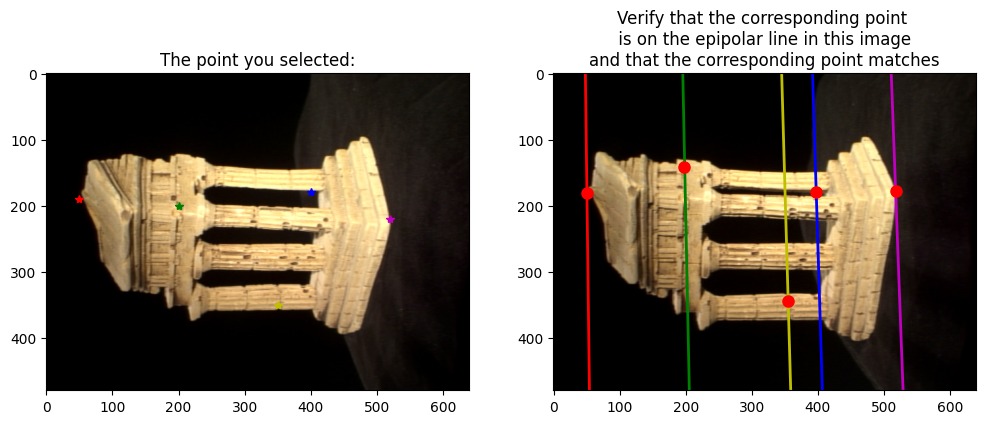

In [ ]:
# the points in im1 whose correnponding epipolar line in im2 you'd like to verify
points = [(50,190), (200, 200), (400,180), (350,350), (520, 220)]
# feel free to change these points to verify different point correspondences
epipolarMatchGUI(im1, im2, F, points, epipolarCorrespondence)

### 3.2 Temple Visualization (5 points)

Included in this homework is a file *data/templeCoords.npz* which contains 288 hand-selected points from `im1` saved in the variables `x1` and `y1`.

Now, we can determine the 3D location of these point correspondences using the `triangulate` function. These 3D point locations can then plotted using the `matplotlib` package. Complete the `compute3D_pts` function, which loads the necessary files from *data/* to generate the 3D reconstruction using `scatter` function `matplotlib`. An example is shown in Figure 3. **Make sure you show the reconstructed 3d points in your submission.**

![Figure 3](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw3/fig5.png)
*Figure 3:* An example point cloud.

In [ ]:
def compute3D_pts(temple_pts1, intrinsics, F, im1, im2):
  '''
  Q3.2: Finding the 3D position of given points based on epipolar correspondence and triangulation
  Input:  temple_pts1, chosen points from im1
          intrinsics, the intrinsics dictionary for calling epipolarCorrespondence
          F, the fundamental matrix
          im1, the first image
          im2, the second image
  Output: P (Nx3) the recovered 3D points

  Hints:
  (1) Use epipolarCorrespondence to find the corresponding point for [x1 y1] (find [x2, y2])
  (2) Now you have a set of corresponding points [x1, y1] and [x2, y2], you can compute the M2
      matrix and use triangulate to find the 3D points.
  (3) Use the function findM2 to find the 3D points P (do not recalculate fundamental matrices)
  (4) As a reference, our solution's best error is around ~750 on the 3D points.
  '''
  N = len(temple_pts1)
  temple_pts2 = np.ones((N, 2))

  for i in range(N):
    x1, y1 = temple_pts1[i]
    x2, y2 = epipolarCorrespondence(im1, im2, F, x1, y1)
    temple_pts2[i] = np.array([x2, y2])

  M2, C2, P = findM2(F, temple_pts1, temple_pts2, intrinsics)
  return P


Below, integrate everything together.
The provided starter code loads in the temple data found at *data/templeCoords.npz*, which contains the 288 hand-selected points from `im1` saved in the variables `x1` and `y1`.
Then, get the 3d points from the 2d point point correspondences by calling the function you just implemented, as well as other necessary function. Finally, visualize the 3D reconstruction using `matplotlib` scatter plot.


best M2 [[ 0.99942697  0.03331533  0.00598477 -0.02599827]
 [-0.03372859  0.96531605  0.25889634 -1.        ]
 [ 0.00284802 -0.25894984  0.96588657  0.07961991]]


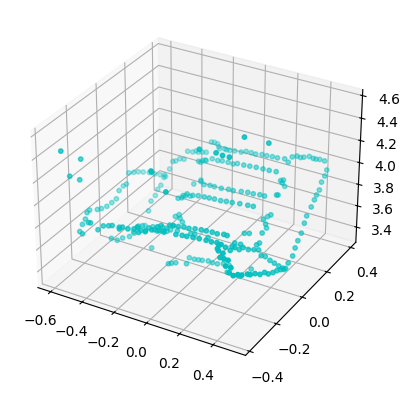

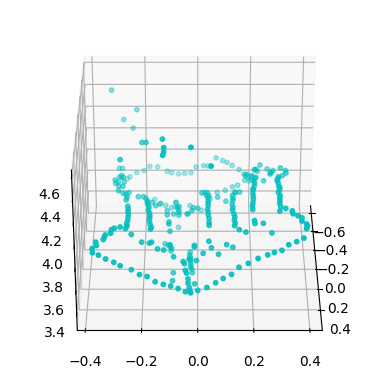

In [ ]:
temple_coords = np.load('data/templeCoords.npz') # Loading temple coordinates
correspondence = np.load('data/some_corresp.npz') # Loading correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')

# ----- TODO -----
# Call eightpoint to get the F matrix
# Call compute3D_pts to get the 3D points and visualize using matplotlib scatter
# hint: you can change the viewpoint of a matplotlib 3d axes using
# `ax.view_init(azim, elev)` where azim is the rotation around the vertical z
# axis, and elev is the angle of elevation from the x-y plane

temple_pts1 = np.hstack([temple_coords['x1'], temple_coords['y1']])

M = np.max([*im1.shape, *im2.shape])
F = eightpoint(pts1, pts2, M)

P = compute3D_pts(temple_pts1, intrinsics, F, im1, im2)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=10, c='c', depthshade=True)
plt.draw()

# also show a different viewpoint
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=10, c='c', depthshade=True)
ax.view_init(30, 0)
plt.draw()


---
## Section 4: Bundle Adjustment

Bundle Adjustment is commonly used as the last step of every feature-based 3D reconstruction algorithm. Given a set of images depicting a number of 3D points from different viewpoints, bundle adjustment is the process of simultaneously refining the 3D coordinates along with the camera parameters. It minimizes reprojection error, which is the squared sum of distances between image points and predicted points. In this section, you will implement bundle adjustment algorithm by yourself.

In some real world applications, manually determining correspondences is infeasible and often there will be noisy correspondences. Fortunately, the RANSAC method seen in class can be applied to the problem of fundamental matrix estimation.

### Preliminaries: RANSAC, Rodrigues, and Inverse Rodrigues

You implemented RANSAC for more accurate estimation of the homography matrix using 4 pairs of point correspondences at a time. Provided for you is a RANSAC function which estimates a fundamental matrix using 8 pairs of point correspondences at a time (using the eightpoint algorithm you previously implemented). We will use the fundamental matrix estimation from RANSAC and our previously written `findM2` function to initialize our camera parameters before we do Bundle Adjustment.

So far we have independently solved for camera matrix, $\mathbf{M}_j$ and 3D points $w_i$. In bundle adjustment, we will jointly optimize the reprojection error with respect to the points $w_i$ and the camera matrix $C_j$.
$$err = \sum_{ij} \|x_{ij} - Proj(\mathbf{C}_j, w_i)\|^2$$
where $C_j = \mathbf{K}_j \mathbf{M}_j$.

Below is the implementation of RANSAC for Fundamental Matrix Recovery.

In [ ]:
def ransacF(pts1, pts2, M, nIters=100, tol=10):
  '''
  Input:  pts1, Nx2 Matrix
          pts2, Nx2 Matrix
          M, a scaler parameter
          nIters, Number of iterations of the Ransac
          tol, tolerence for inliers
  Output: F, the fundamental matrix
          inliers, Nx1 bool vector set to true for inliers

  '''
  N = pts1.shape[0]
  pts1_homo, pts2_homo = toHomogenous(pts1), toHomogenous(pts2)
  best_inlier = 0
  inlier_curr = None

  for i in range(nIters):
      choice = np.random.choice(range(pts1.shape[0]), 8)
      pts1_choice = pts1[choice, :]
      pts2_choice = pts2[choice, :]
      F = eightpoint(pts1_choice, pts2_choice, M)
      ress = calc_epi_error(pts1_homo, pts2_homo, F)
      curr_num_inliner = np.sum(ress < tol)
      if curr_num_inliner > best_inlier:
          F_curr = F
          inlier_curr = (ress < tol)
          best_inlier = curr_num_inliner
  inlier_curr = inlier_curr.reshape(inlier_curr.shape[0], 1)
  indixing_array = inlier_curr.flatten()
  pts1_inlier = pts1[indixing_array]
  pts2_inlier = pts2[indixing_array]
  F = eightpoint(pts1_inlier, pts2_inlier, M)
  return F, inlier_curr

For this homework, we are going to only look at optimizing the extrinsic matrix. To do this we will be parameterizing the rotation matrix `R` using Rodrigues formula to produce vector `r` $\in \mathbb{R}^3$. The Rodrigues formula converts a Rodrigues vector `r` to a rotation matrix `R`:
```
R = rodrigues(r)
```
and the inverse function that converts a rotation matrix `R` to a Rodrigues vector `r`:
```
r = invRodrigues(R)
```
Below is the implementation of Rodrigues and Inverse Rodrigues Formulas, but please view the following references for details as you will need to understand how to use it: [Rodrigues formula](https://en.wikipedia.org/wiki/Rodrigues\%27\_formula) and [this pdf](https://www2.cs.duke.edu/courses/fall13/compsci527/notes/rodrigues.pdf).

In [ ]:
def rodrigues(r):
  '''
  Input:  r, a 3x1 vector
  Output: R, a rotation matrix
  '''

  r = np.array(r).flatten()
  I = np.eye(3)
  theta = np.linalg.norm(r)
  if theta == 0:
      return I
  else:
      U = (r/theta)[:, np.newaxis]
      Ux, Uy, Uz = r/theta
      K = np.array([[0, -Uz, Uy], [Uz, 0, -Ux], [-Uy, Ux, 0]])
      R = I * np.cos(theta) + np.sin(theta) * K + \
          (1 - np.cos(theta)) * np.matmul(U, U.T)
  return R


def invRodrigues(R):
  '''
  Input:  R, a rotation matrix
  Output: r, a 3x1 vector
  '''

  def s_half(r):
      r1, r2, r3 = r
      if np.linalg.norm(r) == np.pi and (r1 == r2 and r1 == 0 and r2 == 0 and r3 < 0) or (r1 == 0 and r2 < 0) or (r1 < 0):
          return -r
      else:
          return r

  A = (R - R.T)/2
  ro = [A[2, 1], A[0, 2], A[1, 0]]
  s = np.linalg.norm(ro)
  c = (np.sum(np.matrix(R).diagonal()) - 1)/2
  if s == 0 and c == 1:
      r = np.zeros(3)
  elif s == 0 and c == -1:
      col = np.eye(3) + R
      col_idx = np.nonzero(
          np.array(np.sum(col != 0, axis=0)).flatten())[0][0]
      v = col[:, col_idx]
      u = v/np.linalg.norm(v)
      r = s_half(u * np.pi)
  else:
      u = ro/s
      theta = np.arctan2(s, c)
      r = u * theta

  return r

### 4.1 Bundle adjustment (20 points)

Using this parameterization, write the objective function `rodriguesResidual`:
```
residuals = rodriguesResidual(K1, M1, p1, K2, p2, x)
```
where `x` is the flattened concatenation of `P`, `r2`, and `t2`. `P` are the 3D points; `r2` and `t2` are the rotation (in the Rodrigues vector form) and translation vectors associated with the projection matrix `M2`. The `residuals` are the difference between original image projections and estimated projections (the square of L2-norm of this vector corresponds to the error we computed in 2.2):
```
residuals = numpy.concatenate([(p1-p1_hat).reshape([-1]), (p2-p2_hat).reshape([-1])])
```

In [ ]:
def rodriguesResidual(K1, M1, p1, K2, p2, x):
  '''
  Q4.1: Rodrigues residual.
    Input:  K1, the intrinsics of camera 1
            M1, the extrinsics of camera 1
            p1, the 2D coordinates of points in image 1
            K2, the intrinsics of camera 2
            p2, the 2D coordinates of points in image 2
            x, the flattened concatenationg of P, r2, and t2.
    Output: residuals, 4N x 1 vector, the difference between original and estimated projections
  '''
  N = p1.shape[0]
  P = x[:-6].reshape(N, 3)
  r2 = x[-6: -3]
  t2 = x[-3:]

  R2 = rodrigues(r2)
  M2 = np.hstack((R2, t2.reshape(3, 1)))
  C1 = K1 @ M1
  C2 = K2 @ M2
  P_h = np.hstack((P, np.ones((N, 1))))

  p1_hat = (C1 @ P_h.T).T
  p2_hat = (C2 @ P_h.T).T
  p1_hat = p1_hat[:, :2] / p1_hat[:, 2:3]
  p2_hat = p2_hat[:, :2] / p2_hat[:, 2:3]

  residuals = np.concatenate([(p1-p1_hat).reshape([-1]), (p2-p2_hat).reshape([-1])])

  return residuals


Then, use this error function and Scipy's optimizer `minimize` to implement `bundleAdjustment`. This function will optimize for the best extrinsic matrix and 3D points using the inlier correspondences from *data/some_corresp_noisy.npz*, using the RANSAC estimate of the extrinsics and 3D points as an initialization.
```
[M2, w, o1, o2] = bundleAdjustment(K1, M1, p1, K2, M2_init, p2, w_init)
```
Try to extract the rotation and translation from `M2_init`, then use `invRodrigues` you implemented previously to transform the rotation, concatenate it with translation and the 3D points, then the concatenate vector are variables to be optimized. After obtaining optimized vector, decompose it back to rotation using `rodrigues` you implemented previously, translation and 3D points coordinates.

Use `ransacF`, `findM2`, and your implemented `bundleAdjustment` to put it all together. Report the reprojection error with your initial `M2_init` and `w_init`, as well as with the optimized matrices. Show the before and after for bundle adjustment, a la Figure 4.

*Hint:* For reference, our solution achieves a reprojection error around 10 after optimization. Your exact error may differ slightly.

![Figure 4](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw3/fig6.png)
*Figure 4:* Visualization of 3D points for noisy correspondences before and after using bundle adjustment.

In [ ]:
def bundleAdjustment(K1, M1, p1, K2, M2_init, p2, P_init):
  '''
  Q4.1: Bundle adjustment.
  Input:  K1, the intrinsics of camera 1
          M1, the extrinsics of camera 1
          p1, the 2D coordinates of points in image 1
          K2,  the intrinsics of camera 2
          M2_init, the initial extrinsics of camera 1
          p2, the 2D coordinates of points in image 2
          P_init, the initial 3D coordinates of points
  Output: M2, the optimized extrinsics of camera 1
          P2, the optimized 3D coordinates of points
          o1, the starting objective function value with the initial input
          o2, the ending objective function value after bundle adjustment

  Hints:
  (1) Use the scipy.optimize.minimize function to minimize the objective function, rodriguesResidual.
      You can try different (method='..') in scipy.optimize.minimize for best results.
  '''
  obj_start = obj_end = 0

  N = p1.shape[0]
  r2 = invRodrigues(M2_init[:, :3])
  t2 = M2_init[:, 3]
  x_init = np.concatenate([P_init.reshape(-1), r2, t2])

  # we have to define objective
  def obj(x):
    return np.sum(rodriguesResidual(K1, M1, p1, K2, p2, x) ** 2)

  obj_start = obj(x_init)
  result = scipy.optimize.minimize(obj, x_init, method='Powell')
  x = result.x
  P = x[:-6].reshape(N, 3)
  r2 = x[-6: -3]
  t2 = x[-3:]

  M2 = np.hstack((rodrigues(r2), t2.reshape(3, 1)))
  obj_end = obj(x)

  return M2, P, obj_start, obj_end

Putting it all together:

1. Call the ransacF function to find the fundamental matrix
2. Call the findM2 function to find the extrinsics of the second camera
3. Call the bundleAdjustment function to optimize the extrinsics and 3D points
4. Plot the 3D points before and after bundle adjustment using the plot_3D_dual function

On the given temple data, bundle adjustment can take up to 2 min to run.

In [ ]:
# Visualization:
np.random.seed(1)
correspondence = np.load('data/some_corresp_noisy.npz') # Loading noisy correspondences
intrinsics = np.load('data/intrinsics.npz') # Loading the intrinscis of the camera
K1, K2 = intrinsics['K1'], intrinsics['K2']
pts1, pts2 = correspondence['pts1'], correspondence['pts2']
im1 = plt.imread('data/im1.png')
im2 = plt.imread('data/im2.png')
M=np.max([*im1.shape, *im2.shape])

'''
Call the ransacF function to find the fundamental matrix
Call the findM2 function to find the extrinsics of the second camera
Call the bundleAdjustment function to optimize the extrinsics and 3D points
'''
F, inlier = ransacF(pts1, pts2, M)
p1 = pts1[inlier.reshape(-1)]
p2 = pts2[inlier.reshape(-1)]
M1 = np.hstack((np.eye(3), np.zeros((3, 1))))
M2_init, C2_init, P_init = findM2(F, p1, p2, intrinsics)
M2_final, P_final, obj_start, obj_end = bundleAdjustment(K1, M1, p1, K2, M2_init, p2, P_init)

print(f"Before reprojection error: {obj_start}, After: {obj_end}")

best M2 [[ 0.99942699  0.03331512  0.0059828  -0.0260034 ]
 [-0.03372786  0.96531575  0.25889755 -1.        ]
 [ 0.00284991 -0.25895098  0.96588626  0.07966877]]
Before reprojection error: 352.84188191712974, After: 10.905073231792876


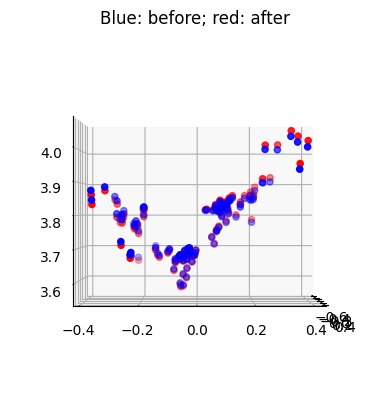

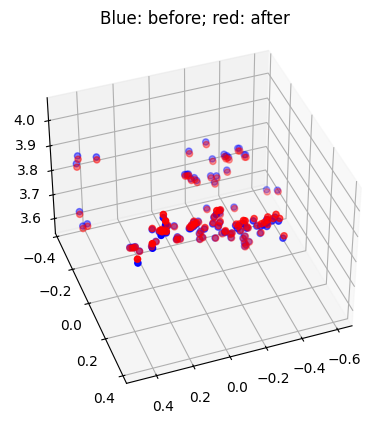

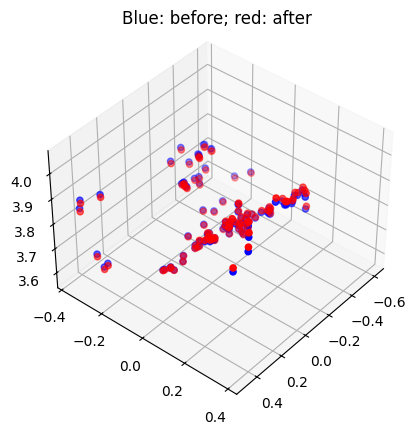

In [ ]:
# helper function for visualization
def plot_3D_dual(P_before, P_after, azim=70, elev=45):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.set_title("Blue: before; red: after")
    ax.scatter(P_before[:,0], P_before[:,1], P_before[:,2], c = 'blue')
    ax.scatter(P_after[:,0], P_after[:,1], P_after[:,2], c='red')
    ax.view_init(azim=azim, elev=elev)
    plt.draw()

# plots the 3d points before and after BA from different viewpoints
plot_3D_dual(P_init, P_final, azim=0, elev=0)
plot_3D_dual(P_init, P_final, azim=70, elev=40)
plot_3D_dual(P_init, P_final, azim=40, elev=40)

### Generate your PDF

Run this cell LAST to generate your PDF. You will be prompted to grant permission. Please click "Select all" and then "Continue." This allows Colab to access the notebook contents to create the PDF (it does not access anything outside your notebook). It may take ~1 minute to complete-please be patient and do not rerun the cell. The PDF (including both your code and its output) will automatically download to your Downloads folder.

### Optional PDF export
Use Jupyter's **Save and Export Notebook As** menu, or Colab's **File → Print**. PDF export is separate from running the project and requires no Drive authorization.
